In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [26]:
dt=pd.read_csv("insurance.csv")

print(dt)
dt.shape

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


(1338, 7)

In [27]:
dt.describe()
#therefore no missing values

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [28]:
#normalistion---from -1 to 1
def featureNormalization(X):
    mean=np.mean(X,axis=0)
    std=np.std(X,axis=0)
    
    X_norm = (X - mean)/std
    
    return X_norm , mean , std

In [29]:
# Returns an array of all unique values in that column
dt['region'].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

In [30]:
dt["sex"] = dt["sex"].map({"male":1, "female":0})
dt["smoker"] = dt["smoker"].map({"yes":1, "no":0})
dt["region"] = dt["region"].map({
    "southwest":0,
    "southeast":1,
    "northwest":2,
    "northeast":3
})

In [31]:
dt_norm=dt.values
m=len(dt_norm)
X=dt_norm[:,0:6].reshape(m,6)
Y = dt_norm[:,6].reshape(m,1)

print(X.shape)
print(Y.shape)

X, mean_X, std_X = featureNormalization(X)
X = np.append(np.ones((m,1)), X, axis=1)

theta = np.zeros((7,1))


(1338, 6)
(1338, 1)


In [32]:
def hypothesis(theta_array,x_row):
    prediction=0
    for i in range(len(theta_array)):
        prediction+=theta_array[i]*x_row[i]
    return prediction

In [33]:
def cost_function(theta_array,x_train,y_train,m):
    total_error=0
    for i in range(m):
        prediction = hypothesis(theta_array, x_train[i])
        total_error += (prediction - y_train[i])**2
    return (total_error/2*m)

In [34]:
def gradient_descent(theta_array, x_train, y_train, m, alpha):

    new_theta = theta_array.copy()
    for j in range(len(theta_array)):
        summation = 0
        for i in range(m):
            prediction = hypothesis(theta_array, x_train[i])
            summation += (prediction - y_train[i]) *x_train[i][j]
        new_theta[j] = theta_array[j] - (alpha/m)*summation
    return new_theta

In [35]:
def training(x_train,y_train,alpha,iters):
    theta_array=np.zeros(7)
    # theta_array=[theta0,theta1,theta2]
    m=x_train.shape[0]
    cost_value=[]
    for i in range(iters):
        theta_array=gradient_descent(theta_array,x_train,y_train,m,alpha)
        cost_value.append(cost_function(theta_array,x_train,y_train,m))
        #y_new=theta_array[0]+theta_array[1]*x1_train+theta_array[2]*x2_train
        # plt.plot(x1_train,y_new,'r')
        # plt.scatter(x1_train,y_train)
        # plt.show()
    plt.figure()
    x=np.arange(0,len(cost_value),step=1)
    plt.plot(x,cost_value)
    plt.xlabel("Number Of Iterations")
    plt.ylabel("Cost Function Value")
    plt.show()
    return theta_array

C:\Users\heerm\AppData\Local\Temp\ipykernel_24812\1468303464.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  new_theta[j] = theta_array[j] - (alpha/m)*summation


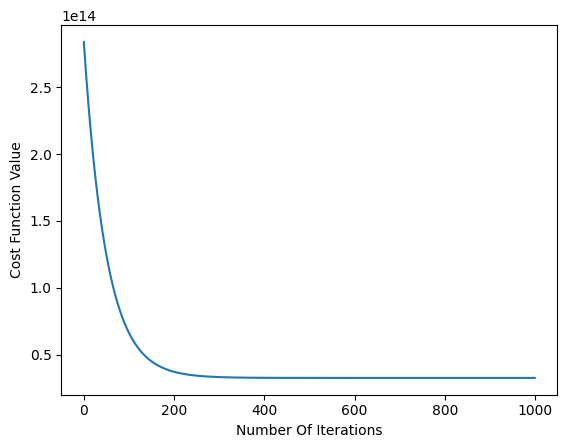

Final Theta Values:
[13269.84936446  3613.34405541   -65.19857446  2027.26398507
   577.71339896  9611.98587224   390.50333746]


In [ ]:
alpha = 0.01
iters = 1000
theta_array = training(X, Y, alpha, iters)
print("Final Theta Values:")
print(theta_array)

C:\Users\heerm\AppData\Local\Temp\ipykernel_24812\1468303464.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  new_theta[j] = theta_array[j] - (alpha/m)*summation


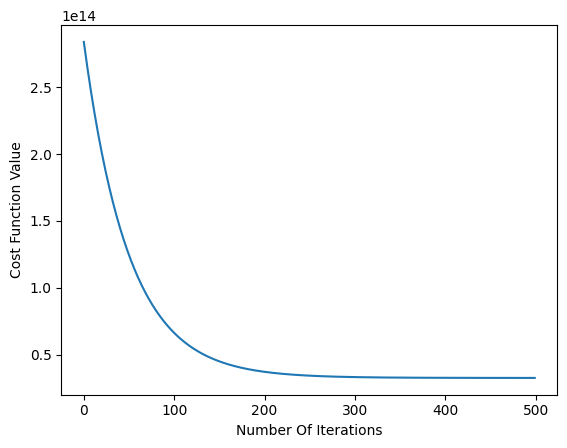

Final Theta Values:
[13183.22918068  3587.80642353   -40.21280103  2020.688706
   580.6181353   9541.64520802   381.48737669]


In [37]:
theta_array = training(X, Y, alpha, 500)
print("Final Theta Values:")
print(theta_array)

C:\Users\heerm\AppData\Local\Temp\ipykernel_24812\1468303464.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  new_theta[j] = theta_array[j] - (alpha/m)*summation


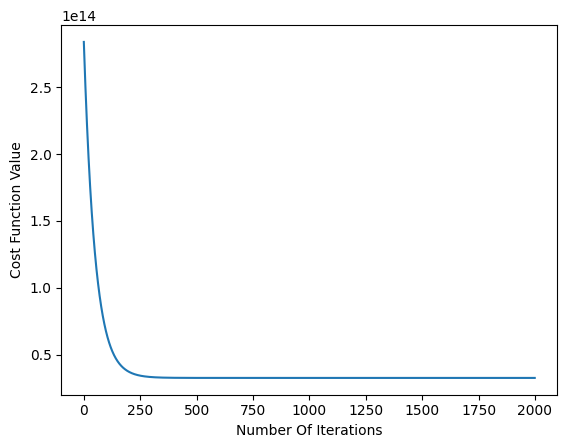

Final Theta Values:
[13270.42224041  3613.53614464   -65.55165848  2027.3167958
   577.66033903  9612.57302178   390.58546904]


In [42]:
theta_array = training(X, Y, alpha, 2000)
print("Final Theta Values:")
print(theta_array)

C:\Users\heerm\AppData\Local\Temp\ipykernel_24812\1468303464.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  new_theta[j] = theta_array[j] - (alpha/m)*summation


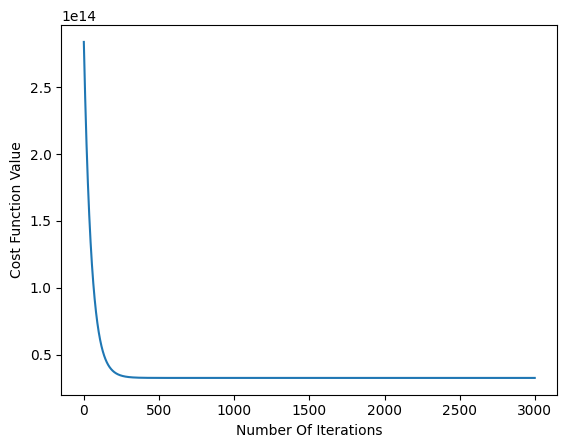

Final Theta Values:
[13270.42226514  3613.53615058   -65.55170114  2027.3168105
   577.66033542  9612.57306988   390.58548033]


In [40]:
theta_array = training(X, Y, alpha, 3000)
print("Final Theta Values:")
print(theta_array)

C:\Users\heerm\AppData\Local\Temp\ipykernel_24812\1468303464.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  new_theta[j] = theta_array[j] - (alpha/m)*summation


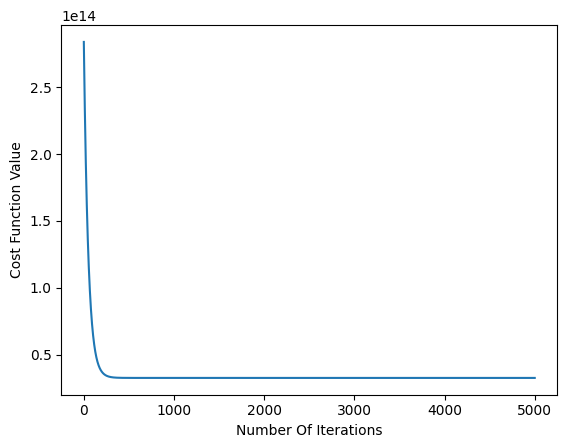

Final Theta Values:
[13270.42226514  3613.53615057   -65.55170114  2027.3168105
   577.66033542  9612.57306988   390.58548034]


In [39]:
theta_array = training(X, Y, alpha, 5000)
print("Final Theta Values:")
print(theta_array)